# Thermodynamic transport theory for the Lennard-Jones fluid: viscosity and self-diffusion

This notebook contains all the calculations of Sec. VII of the paper *Thermodynamic transport theory applied to the Lennard-Jones fluid* (M. Hoyuelos): it produces the figures and the tables of the comparison of the present theory (TTT) and of the revised Enskog theory (RET) with the molecular-dynamics data of Meier for the shear viscosity $\eta$ and the self-diffusion coefficient $D$ of the Lennard-Jones (LJ) fluid at supercritical temperatures. It also gives the errors of TTT with the EOS of Kolafa & Nezbeda and of Lafitte et al., which are mentioned in the paper.

**How to run.** Select a SageMath kernel (tested with SageMath 10.9) and use *Restart Kernel and Run All Cells*. NumPy and SciPy are required. All the simulation data are embedded; no external files are needed. The figures are saved as PDF files in `FIGURE_DIR` (Sec. 8).

**Formulas (reduced LJ units, $k_B=\epsilon=\sigma=m=1$).** For viscosity and self-diffusion the thermodynamic state is uniform, and

$$\frac{\zeta}{\zeta_\text{id}}=\frac{c_\rho}{c^\text{id}_\rho}\,\frac{L_{\tilde x}}{L^\text{id}_{\tilde x}}\,R ,\qquad
\frac{L_{\tilde x}}{L^\text{id}_{\tilde x}}=\frac{c^\text{id}_\rho\,B_a}{(c^\text{id}_\rho+a)\left(a c_\rho-T\,\partial_Tc_\rho\right)},$$

with $B_a=a c_\rho-T\partial_Tc_\rho+2a\rho\,\partial_\rho c_\rho+a^2\Gamma_\text{th}$, $\Gamma_\text{th}=\partial(\rho Z_\text{th})/\partial\rho=\partial(\Gamma T)/\partial T$, $Z_\text{th}=\partial(ZT)/\partial T$ and $c^\text{id}_\rho=3/2$.

| | exponent $a$ | departure factor $R$ |
|---|---|---|
| viscosity | $1/2$ | $R_\perp=Z_\text{th}/\sqrt{\Gamma_\text{th}}$ |
| self-diffusion | $a_D=\tfrac58+\tfrac{25}{8}\left(\Omega^{(1,1)}/\Omega^{(2,2)}-1\right)$ | $R_D=e^{s'_\text{ex}}$ |

For self-diffusion, $a_D$ is evaluated at the temperature of the state and treated as a constant (paper, Sec. VI.B).

**Structure.** 1. Setup and dilute-gas coefficients. 2. Model. 3. Equations of state. 4. Simulation data. 5. Freezing line and comparison tools. 6. Exponent $a_D$. 7. Revised Enskog theory (RET). 8. Figures and tables of the paper.

## 1. Setup and dilute-gas coefficients

Reduced collision integrals: $\Omega^{(1,1)}$ from Meier's thesis (correlation of Fokin et al.), $\Omega^{(2,2)}$ from Fokin et al., as in Bugel & Galliero. The dilute-gas coefficients of viscosity and self-diffusion are in the first Chapman-Enskog approximation. `rhoDid` is $\rho D_\text{id}$, which does not depend on density.

In [1]:
import math
from functools import lru_cache

var('T rho')
c_id = 3/2

omega11_coeffs = [0.125431, -0.167256, -0.265865, 1.59760, -1.19088, 0.264833]
omega22_coeffs = [0.310810, -0.171211, -0.715805, 2.48678, -1.78317, 0.394405]
Omega11 = exp(-1/6*log(T) + sum(omega11_coeffs[i]*sqrt(T)^(-i) for i in range(6)))
Omega22 = exp(-1/6*log(T) + log(17/18) + sum(omega22_coeffs[i]*sqrt(T)^(-i) for i in range(6)))

eta_id    = 5/16*sqrt(T/n(pi))/Omega22    # shear viscosity
rhoD_id   = 3/8*sqrt(T/n(pi))/Omega11     # rho * self-diffusion coefficient

# Exponent of the ideal-form composition density, Eq. (aDOmega), evaluated at the temperature of the state
a_D = 5/8 + 25/8*(Omega11/Omega22 - 1)

colors = ['#e377c2','#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd',
          '#8c564b','#7f7f7f','#bcbd22','#17becf','#1a55FF']
RHO_MAX_MAPE = 1.2      # self-diffusion: densities included in the mean absolute percentage error

## 2. Model

An EOS is a dictionary with the thermodynamic functions of $(\rho,T)$ that the model needs. `make_eos` builds it from the excess Helmholtz energy per particle, $f_\text{ex}(\rho,T)$, in units of $\epsilon$. For EOS that contain functions of $T$ evaluated numerically (Lafitte), the dictionary also carries a `slicer` that substitutes them after differentiation.

In [2]:
def make_eos(name, fex, slicer=None, note=''):
    Z = 1 + rho*diff(fex, rho)/T
    c = c_id - T*diff(fex, T, 2)
    Zth = diff(T*Z, T)
    e = dict(name=name, note=note, slicer=slicer, fex=fex,
             Z=Z, c=c, Gamma=diff(rho*Z, rho), Zth=Zth, Gth=diff(rho*Zth, rho),
             sex=-diff(fex, T), cT=diff(c, T), cr=diff(c, rho))
    return e

def L_ratio(e, a):
    # L_x / L_x^id, Eq. (Lx)
    c, cT, cr, Gth = e['c'], e['cT'], e['cr'], e['Gth']
    B = a*c - T*cT + 2*a*rho*cr + a^2*Gth
    return c_id*B/((c_id + a)*(a*c - T*cT))

def ratio_uniform(e, a):
    # D_x / D_x^id for viscosity and self-diffusion, Eq. (DratioU)
    return e['c']/c_id*L_ratio(e, a)

def models(e):
    # Symbolic predictions in reduced units: rho*D and eta
    R_perp = e['Zth']/sqrt(e['Gth'])
    R_D = exp(e['sex'])
    return {
        'rhoD':      rhoD_id*ratio_uniform(e, a_D)*R_D,
        'eta':       eta_id*ratio_uniform(e, 1/2)*R_perp,
    }

def isotherm(expr, e, temperature):
    # Fast numerical function of rho at fixed T
    temperature = float(temperature)
    if e['slicer'] is not None:
        expr = e['slicer'](expr, temperature)
    else:
        expr = expr.subs(T=temperature)
    return fast_callable(expr, vars=[rho], domain=RDF)

## 3. Equations of state

All four EOS are written in terms of $f_\text{ex}(\rho,T)$.

* **Thol et al. (2016)**: reference EOS for the full LJ fluid (23-term residual Helmholtz energy).
* **Kolafa & Nezbeda (1994)**: full LJ fluid.
* **Heier et al. (2018), PeTS**: LJ truncated and shifted at $r_c=2.5$. It is used here also for data with larger cutoff, as a test of sensitivity to the EOS.
* **Lafitte et al. (2013), SAFT-VR Mie** with $(12,6)$ exponents: full LJ fluid. The Barker-Henderson diameter $d(T)$ and its derivatives are computed by numerical quadrature and substituted after the symbolic differentiation.

In [3]:
# ---------------- Thol et al. (2016) ----------------
var('tau delta')
Tc_thol, rhoc_thol = 1.32, 0.31
poly = [[0.005208073, 2.186252000, -2.161016000, 1.452700000, -2.041792000, 0.186952860],
        [1.000, 0.320, 0.505, 0.672, 0.843, 0.898],
        [4, 1, 1, 2, 2, 3]]
expo = [[-0.090988445, -0.497456100, 0.109014310, -0.800559220, -0.568839000, -0.620862500],
        [1.294, 2.590, 1.786, 2.770, 1.786, 1.205],
        [5, 2, 2, 3, 1, 1],
        [1, 2, 1, 2, 2, 1]]
gauss = [[-1.466717700, 1.891469000, -0.138370100, -0.386964500, 0.126570200,
          0.605781000, 1.179189000, -0.477326790, -9.921857500, -0.574793200, 0.003772923],
         [2.830, 2.548, 4.650, 1.385, 1.460, 1.351, 0.660, 1.496, 1.830, 1.616, 4.970],
         [1, 1, 2, 3, 3, 2, 1, 2, 3, 1, 1],
         [2.067, 1.522, 8.82, 1.722, 0.679, 1.883, 3.925, 2.461, 28.2, 0.753, 0.82],
         [0.625, 0.638, 3.91, 0.156, 0.157, 0.153, 1.16, 1.73, 383, 0.112, 0.119],
         [0.71, 0.86, 1.94, 1.48, 1.49, 1.945, 3.02, 1.11, 1.17, 1.33, 0.24],
         [0.2053, 0.409, 0.6, 1.203, 1.829, 1.397, 1.39, 0.539, 0.934, 2.369, 2.43]]
alphar = sum(poly[0][i]*delta^poly[2][i]*tau^poly[1][i] for i in range(6))
alphar += sum(expo[0][i]*delta^expo[2][i]*tau^expo[1][i]*exp(-delta^expo[3][i]) for i in range(6))
alphar += sum(gauss[0][i]*delta^gauss[2][i]*tau^gauss[1][i]
              *exp(-gauss[3][i]*(delta - gauss[6][i])^2 - gauss[4][i]*(tau - gauss[5][i])^2)
              for i in range(11))
fex_thol = (T*alphar).subs({delta: rho/rhoc_thol, tau: Tc_thol/T})
eos_thol = make_eos('Thol', fex_thol, note='full LJ')

In [4]:
# ---------------- Kolafa & Nezbeda (1994) ----------------
def kolafa_fex():
    sT = sqrt(T)
    dC = -0.063920968*log(T) + 0.011117524/T - 0.076383859/sT + 1.080142248 + 0.000693129*sT
    isT = 1/sT
    BC = (((((-0.58544978*isT + 0.43102052)*isT + 0.87361369)*isT - 4.13749995)*isT
           + 2.90616279)*isT - 7.02181962)/T + 0.02459877
    gammaBH = 1.92907278
    eta_k = n(pi)/6*rho*dC^3
    betaAHS = log(1 - eta_k)/0.6 + eta_k*((4/6*eta_k - 33/6)*eta_k + 34/6)/(1 - eta_k)^2
    DALJ = ((2.01546797 + rho*(-28.17881636 + rho*(28.28313847 + rho*(-10.42402873))))
            + (-19.58371655 + rho*(75.62340289 + rho*(-120.70586598 + rho*(93.92740328
               + rho*(-27.37737354)))))/sqrt(T)
            + ((29.34470520 + rho*(-112.35356937 + rho*(170.64908980 + rho*(-123.06669187
               + rho*34.42288969))))
               + (-13.37031968 + rho*(65.38059570 + rho*(-115.09233113 + rho*(88.91973082
               + rho*(-25.62099890)))))/T)/T)*rho*rho
    return (betaAHS + rho*BC/exp(gammaBH*rho^2))*T + DALJ
eos_kolafa = make_eos('Kolafa', kolafa_fex(), note='full LJ')

In [5]:
# ---------------- Heier et al. (2018), PeTS: LJ truncated and shifted, r_c = 2.5 ----------------
def heier_fex():
    c1, c2 = 0.127112544, 3.052785558
    a_h = [0.690603404, 1.189317012, 1.265604153, -24.34554201, 93.67300357, -157.8773415, 96.93736697]
    b_h = [0.664852128, 2.10733079, -9.597951213, -17.37871193, 30.17506222, 209.3942909, -353.2743581]
    d_h = 1 - c1*exp(-c2/T)                       # effective diameter, Eq. (6)
    eta_h = n(pi)/6*rho*d_h^3                     # packing fraction, Eq. (8)
    a_hs = eta_h*(4 - 3*eta_h)/(1 - eta_h)^2      # Carnahan-Starling, Eq. (7)
    I1 = sum(a_h[i]*eta_h^i for i in range(7))    # Eq. (12)
    I2 = sum(b_h[i]*eta_h^i for i in range(7))    # Eq. (13)
    zeta_h = (8*eta_h - 2*eta_h^2)/(1 - eta_h)^4
    a_res = a_hs - 2*n(pi)*rho*I1/T - n(pi)*rho*I2/((1 + zeta_h)*T^2)   # A^res/(N k T)
    return T*a_res
eos_heier = make_eos('Heier', heier_fex(), note='LJTS, r_c = 2.5')

In [6]:
# Lafitte et al. (2013), SAFT-VR Mie, monomeric LJ (12-6).
# J. Chem. Phys. 139, 154504; DOI: 10.1063/1.4819786.
# Full LJ: m=1, sigma=epsilon=k_B=1; no chain or association contributions.
# Equations (7), (10)-(11), (16)-(20), (28)-(29), (33)-(34), (36), (39)-(41).
def bh_integrand(r, temperature, order):
    # Differentiate the BH integral analytically, then integrate numerically.
    if r <= 1.e-12:
        return 1.0 if order == 0 else 0.0
    q = 4.0*(r**(-12) - r**(-6))/temperature
    if q > 700.0:
        return 1.0 if order == 0 else 0.0
    weight = math.exp(-q)
    if order == 0:
        return -math.expm1(-q)
    if order == 1:
        return -q*weight/temperature
    if order == 2:
        return (2*q - q**2)*weight/temperature**2
    return (-6*q + 6*q**2 - q**3)*weight/temperature**3

@lru_cache(maxsize=None)
def bh_diameter_derivatives(temperature):
    # Return d(T), d'(T), d''(T), d'''(T); double-precision quadrature.
    temperature = float(temperature)
    if temperature <= 0:
        raise ValueError("The BH diameter requires T > 0.")
    return tuple(numerical_integral(
        lambda r: bh_integrand(r, temperature, order), 0.0, 1.0,
        eps_abs=1.e-12, eps_rel=1.e-12)[0] for order in range(4))

# Keep d(T) symbolic during differentiation to retain all temperature terms.
d_lafitte = function('d_lafitte')
dl = d_lafitte(T)
eta_l = n(pi)/6*rho*dl^3
x0_l = 1/dl
eta_sigma_l = n(pi)/6*rho
C_l, alpha_l = 4, 8/9

# Table II: one row per f_i, with coefficients ordered n=0,...,6.
phi_l = [
    (7.5365557, -37.60463, 71.745953, -46.83552, -2.467982, -0.50272, 8.0956883),
    (-359.44, 1825.6, -3168.0, 1884.2, -0.82376, -3.1935, 3.7090),
    (1550.9, -5070.1, 6534.6, -3288.7, -2.7171, 2.0883, 0),
    (-1.19932, 9.063632, -17.9482, 11.34027, 20.52142, -56.6377, 40.53683),
    (-1911.28, 21390.175, -51320.7, 37064.54, 1103.742, -3264.61, 2556.181),
    (9236.9, -129430, 357230, -315530, 1390.2, -4518.2, 4241.6),
]
f_l = [sum(row[j]*alpha_l^j for j in range(4)) /
       (1 + sum(row[j]*alpha_l^(j-3) for j in range(4, 7))) for row in phi_l]
mvt_l = [
    (0.81096, 1.7888, -37.578, 92.284),
    (1.0205, -19.341, 151.26, -463.50),
    (-1.9057, 22.845, -228.14, 973.92),
    (1.0885, -6.1962, 106.98, -677.64),
]

def lafitte_sutherland(exponent):
    # Return a_1^S(eta; exponent) + B(eta; exponent).
    coefficients = [sum(row[j]/exponent^j for j in range(4)) for row in mvt_l]
    eta_eff = sum(coefficients[j]*eta_l^(j+1) for j in range(4))
    a1s = -12*eta_l/(exponent-3)*(1-eta_eff/2)/(1-eta_eff)^3
    integral_i = (1-x0_l^(3-exponent))/(exponent-3)
    integral_j = ((1-x0_l^(4-exponent))/(exponent-4) - integral_i)
    B = 12*eta_l*((1-eta_l/2)*integral_i -
                  9*eta_l*(1+eta_l)*integral_j/2)/(1-eta_l)^3
    return a1s + B

s_l = {exponent: lafitte_sutherland(exponent) for exponent in [6, 12, 18, 24]}
ahs_l = (4*eta_l-3*eta_l^2)/(1-eta_l)^2
khs_l = (1-eta_l)^4/(1+4*eta_l+4*eta_l^2-4*eta_l^3+eta_l^4)
chi_l = f_l[0]*eta_sigma_l + f_l[1]*eta_sigma_l^5 + f_l[2]*eta_sigma_l^8
a1_l = C_l*(x0_l^6*s_l[6] - x0_l^12*s_l[12])
a2_l = C_l^2/2*khs_l*(1+chi_l)*(
    x0_l^12*s_l[12] - 2*x0_l^18*s_l[18] + x0_l^24*s_l[24])
a3_l = -f_l[3]*eta_sigma_l*exp(f_l[4]*eta_sigma_l + f_l[5]*eta_sigma_l^2)
ares_l = ahs_l + a1_l/T + a2_l/T^2 + a3_l/T^3

fex_lafitte = T*ares_l

bh_terms = [dl] + [diff(dl, T, order) for order in range(1, 4)]

def temperature_slice(expression, temperature):
    # Substitute BH derivatives only AFTER all symbolic thermodynamic derivatives.
    # Use this helper also to evaluate cvl, Zl, Gammal, sexl, or the diffusion expression at fixed T.
    if expression.has(dl):
        values = bh_diameter_derivatives(float(temperature))
        for term, value in reversed(list(zip(bh_terms, values))):
            expression = expression.subs({term: value})
    return expression.subs({T: temperature})



eos_lafitte = make_eos('Lafitte', fex_lafitte, slicer=temperature_slice, note='full LJ')

EOS = [eos_thol, eos_kolafa, eos_lafitte, eos_heier]
MODELS = {e['name']: models(e) for e in EOS}

## 4. Simulation data

Meier (thesis; Meier, Laesecke & Kabelac), full LJ fluid: self-diffusion as $[\rho^*, \rho^*D^*]$ and viscosity as $[\rho^*, \eta^*]$.

In [7]:
# ---------------- Self-diffusion ----------------
T_meier = [0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.25, 1.3, 1.35, 1.5, 1.8, 2.1, 2.5, 3.0, 4.0, 6.0]
# Meier: [rho*, rho* D*]
MT = [[[0.85, 0.02523], [0.015, 0.098356], [0.8, 0.034288], [0.01, 0.099717], [0.75, 0.043512], [0.005, 0.101038]], [[0.85, 0.031308], [0.025, 0.11142], [0.8, 0.041126], [0.02, 0.11284], [0.75, 0.051671], [0.015, 0.11375], [0.7, 0.06169], [0.01, 0.11447], [0.03, 0.11119], [0.005, 0.11657]], [[0.85, 0.037227], [0.035, 0.12678], [0.8, 0.047808], [0.03, 0.12589], [0.75, 0.058614], [0.025, 0.12768], [0.7, 0.070064], [0.02, 0.12805], [0.65, 0.081013], [0.015, 0.12918], [0.05, 0.12494], [0.01, 0.12982], [0.045, 0.12492], [0.005, 0.13121], [0.04, 0.12557]], [[0.9, 0.03299], [0.05, 0.14054], [0.85, 0.043307], [0.045, 0.14079], [0.8, 0.054597], [0.04, 0.14106], [0.75, 0.067075], [0.035, 0.1413], [0.7, 0.077777], [0.03, 0.14299], [0.65, 0.08997], [0.025, 0.14265], [0.6, 0.10006], [0.02, 0.14395], [0.07, 0.14086], [0.015, 0.14381], [0.065, 0.14091], [0.01, 0.14536], [0.06, 0.14078], [0.005, 0.14703], [0.055, 0.13984]], [[0.9, 0.038168], [0.06, 0.15548], [0.85, 0.04937], [0.055, 0.15516], [0.8, 0.061452], [0.05, 0.15481], [0.75, 0.073592], [0.045, 0.15597], [0.7, 0.086414], [0.04, 0.15575], [0.65, 0.097668], [0.035, 0.15581], [0.6, 0.10893], [0.03, 0.15758], [0.575, 0.11489], [0.025, 0.1572], [0.55, 0.11967], [0.02, 0.15874], [0.525, 0.12426], [0.015, 0.15934], [0.07, 0.15407], [0.01, 0.15922], [0.065, 0.1546], [0.005, 0.15893]], [[0.95, 0.032908], [0.55, 0.12888], [0.9, 0.043838], [0.5, 0.13875], [0.85, 0.055429], [0.125, 0.17003], [0.8, 0.068306], [0.1, 0.16962], [0.75, 0.081339], [0.075, 0.16929], [0.7, 0.094441], [0.05, 0.16968], [0.65, 0.10631], [0.025, 0.17221], [0.6, 0.11851]], [[0.95, 0.035249], [0.45, 0.15351], [0.9, 0.046456], [0.2, 0.17957], [0.85, 0.058334], [0.175, 0.17895], [0.8, 0.071306], [0.15, 0.17793], [0.75, 0.084653], [0.125, 0.17791], [0.7, 0.097252], [0.1, 0.17618], [0.65, 0.11082], [0.075, 0.17654], [0.6, 0.12251], [0.05, 0.17707], [0.55, 0.13476], [0.025, 0.17852], [0.5, 0.14432]], [[0.95, 0.037745], [0.45, 0.1586], [0.9, 0.049224], [0.225, 0.18367], [0.9, 0.04941], [0.2, 0.18464], [0.85, 0.061663], [0.175, 0.18514], [0.8, 0.074748], [0.15, 0.18421], [0.75, 0.088002], [0.125, 0.18337], [0.7, 0.1016], [0.1, 0.18415], [0.65, 0.1154], [0.075, 0.18352], [0.6, 0.12735], [0.05, 0.18405], [0.55, 0.13961], [0.025, 0.18642], [0.5, 0.14942]], [[0.95, 0.040274], [0.45, 0.16432], [0.9, 0.05194], [0.4, 0.17278], [0.85, 0.064843], [0.35, 0.18051], [0.8, 0.077797], [0.3, 0.18389], [0.75, 0.091678], [0.3, 0.18352], [0.7, 0.10514], [0.25, 0.18955], [0.65, 0.1187], [0.2, 0.1903], [0.6, 0.13182], [0.15, 0.19124], [0.55, 0.14319], [0.1, 0.19065], [0.5, 0.15385], [0.05, 0.19047]], [[0.95, 0.047426], [0.35, 0.19641], [0.9, 0.06055], [0.3, 0.20132], [0.85, 0.073902], [0.25, 0.20538], [0.8, 0.087767], [0.2, 0.20924], [0.75, 0.10282], [0.175, 0.20955], [0.7, 0.11672], [0.15, 0.21029], [0.65, 0.13095], [0.125, 0.20971], [0.6, 0.14461], [0.1, 0.20996], [0.55, 0.15708], [0.075, 0.21031], [0.5, 0.16838], [0.05, 0.21046], [0.45, 0.17909], [0.025, 0.21264], [0.4, 0.18818]], [[1.0, 0.049399], [0.4, 0.21569], [0.95, 0.062691], [0.35, 0.22414], [0.9, 0.077095], [0.3, 0.23233], [0.85, 0.091916], [0.25, 0.23883], [0.8, 0.10789], [0.2, 0.24314], [0.75, 0.12309], [0.175, 0.24405], [0.7, 0.13857], [0.15, 0.24518], [0.65, 0.15346], [0.125, 0.24603], [0.6, 0.16836], [0.1, 0.24679], [0.55, 0.18204], [0.075, 0.24732], [0.5, 0.19488], [0.05, 0.24841], [0.45, 0.20546], [0.025, 0.25119]], [[1.0, 0.063812], [0.4, 0.24185], [0.95, 0.078265], [0.35, 0.25165], [0.9, 0.093509], [0.3, 0.26109], [0.85, 0.10994], [0.25, 0.26657], [0.8, 0.12609], [0.2, 0.27296], [0.75, 0.14352], [0.175, 0.27611], [0.7, 0.15957], [0.15, 0.27688], [0.65, 0.17581], [0.125, 0.27889], [0.6, 0.19032], [0.1, 0.27968], [0.55, 0.20502], [0.075, 0.28147], [0.5, 0.21864], [0.05, 0.28266], [0.45, 0.23127], [0.025, 0.28678]], [[1.05, 0.066637], [0.4, 0.27456], [1.0, 0.082244], [0.35, 0.28481], [0.95, 0.098625], [0.3, 0.2944], [0.9, 0.11578], [0.25, 0.304], [0.85, 0.13341], [0.2, 0.31077], [0.8, 0.15101], [0.175, 0.31333], [0.75, 0.16966], [0.15, 0.31634], [0.7, 0.18709], [0.125, 0.31927], [0.65, 0.20458], [0.1, 0.32168], [0.6, 0.22034], [0.075, 0.32346], [0.55, 0.23614], [0.05, 0.32624], [0.5, 0.24979], [0.025, 0.33036], [0.45, 0.26197]], [[1.1, 0.072006], [0.4, 0.31266], [1.05, 0.088295], [0.35, 0.32362], [1.0, 0.10556], [0.35, 0.32436], [0.95, 0.12399], [0.3, 0.33378], [0.9, 0.14297], [0.3, 0.33452], [0.85, 0.16246], [0.25, 0.34424], [0.8, 0.18168], [0.25, 0.34357], [0.75, 0.20075], [0.2, 0.35303], [0.7, 0.22], [0.175, 0.35733], [0.65, 0.23936], [0.15, 0.36237], [0.6, 0.25564], [0.125, 0.36608], [0.55, 0.27084], [0.1, 0.36958], [0.5, 0.28829], [0.075, 0.37318], [0.45, 0.30209], [0.05, 0.37732], [0.4, 0.31244], [0.025, 0.38126]], [[1.15, 0.093536], [0.45, 0.37071], [1.1, 0.11264], [0.4, 0.38354], [1.05, 0.13172], [0.35, 0.39618], [1.0, 0.15274], [0.3, 0.40851], [0.95, 0.17353], [0.25, 0.42083], [0.9, 0.1954], [0.2, 0.43174], [0.85, 0.21755], [0.175, 0.43743], [0.8, 0.24016], [0.15, 0.4427], [0.75, 0.26093], [0.125, 0.44875], [0.7, 0.28159], [0.1, 0.45538], [0.65, 0.30113], [0.075, 0.46079], [0.6, 0.32138], [0.05, 0.46825], [0.55, 0.33788], [0.025, 0.47242], [0.5, 0.35455]], [[1.275, 0.11381], [0.55, 0.45717], [1.25, 0.12406], [0.5, 0.47618], [1.2, 0.14588], [0.45, 0.49065], [1.15, 0.16838], [0.4, 0.50654], [1.1, 0.19281], [0.35, 0.52188], [1.05, 0.21776], [0.3, 0.5376], [1.0, 0.24378], [0.25, 0.55419], [0.95, 0.26993], [0.2, 0.56964], [0.9, 0.29566], [0.175, 0.57858], [0.85, 0.32151], [0.15, 0.58458], [0.8, 0.34626], [0.125, 0.59322], [0.75, 0.37069], [0.1, 0.60117], [0.7, 0.39464], [0.075, 0.61311], [0.65, 0.4152], [0.05, 0.62391], [0.6, 0.43706], [0.025, 0.63321]]]

D_meier = dict(zip(T_meier, MT))

In [8]:
# ---------------- Viscosity ----------------
# Meier: [rho*, eta*]
visc_0_7 = [[0.85, 3.515], [0.8, 2.380], [0.75, 1.628], [0.015, 0.07550], [0.015, 0.07687], [0.01, 0.07543], [0.01, 0.07720], [0.005, 0.04947], [0.005, 0.07383]]
visc_0_8 = [[0.85, 3.246], [0.8, 2.164], [0.75, 1.646], [0.7, 1.233], [0.03, 0.08567], [0.03, 0.08943], [0.025, 0.09540], [0.025, 0.09009], [0.02, 0.08465], [0.02, 0.08830], [0.015, 0.07473], [0.015, 0.08527], [0.01, 0.07673], [0.01, 0.08895], [0.005, 0.09158]]
visc_0_9 = [[0.85, 2.918], [0.8, 2.095], [0.75, 1.573], [0.7, 1.237], [0.65, 0.9708], [0.05, 0.1090], [0.05, 0.1051], [0.045, 0.1077], [0.045, 0.1029], [0.04, 0.1044], [0.04, 0.1030], [0.035, 0.09796], [0.035, 0.1034], [0.03, 0.1001], [0.03, 0.1014], [0.025, 0.09601], [0.025, 0.09764], [0.02, 0.1012], [0.02, 0.09945], [0.015, 0.1035], [0.015, 0.1002], [0.01, 0.09682], [0.01, 0.09835], [0.005, 0.08578], [0.005, 0.09924]]
visc_1_0 = [[0.9, 3.969], [0.85, 2.833], [0.8, 2.053], [0.75, 1.558], [0.7, 1.222], [0.65, 0.9427], [0.6, 0.7631], [0.07, 0.1193], [0.07, 0.1236], [0.065, 0.1203], [0.06, 0.1215], [0.06, 0.1191], [0.055, 0.1164], [0.05, 0.1045], [0.05, 0.1191], [0.045, 0.1084], [0.04, 0.1280], [0.04, 0.1168], [0.035, 0.09249], [0.03, 0.1212], [0.03, 0.1145], [0.025, 0.1230], [0.02, 0.1102], [0.02, 0.1114], [0.015, 0.1222], [0.01, 0.1134], [0.01, 0.1147], [0.005, 0.07796]]
visc_1_1 = [[0.9, 3.814], [0.85, 2.623], [0.8, 2.019], [0.75, 1.525], [0.7, 1.201], [0.65, 0.9780], [0.575, 0.7334], [0.55, 0.6692], [0.525, 0.5993], [0.07, 0.1267], [0.07, 0.1331], [0.065, 0.1370], [0.06, 0.1373], [0.06, 0.1294], [0.055, 0.1311], [0.05, 0.1205], [0.05, 0.1276], [0.045, 0.1331], [0.04, 0.1269], [0.035, 0.1307], [0.03, 0.1230], [0.03, 0.1254], [0.025, 0.1186], [0.02, 0.1082], [0.02, 0.1229], [0.015, 0.1185], [0.01, 0.1194], [0.01, 0.1242], [0.005, 0.09852]]
visc_1_2 = [[0.95, 5.130], [0.9, 3.627], [0.85, 2.658], [0.8, 1.967], [0.75, 1.534], [0.7, 1.190], [0.65, 0.9842], [0.6, 0.8070], [0.55, 0.6651], [0.5, 0.5748], [0.15, 0.1796], [0.125, 0.1806], [0.125, 0.1661], [0.1, 0.1558], [0.1, 0.1535], [0.075, 0.1559], [0.075, 0.1467], [0.05, 0.1377], [0.05, 0.1418], [0.025, 0.1243], [0.025, 0.1366]]
visc_1_25 = [[0.95, 5.113], [0.9, 3.640], [0.85, 2.593], [0.8, 1.947], [0.75, 1.493], [0.7, 1.219], [0.65, 0.9856], [0.6, 0.7977], [0.55, 0.6649], [0.5, 0.5699], [0.45, 0.4801], [0.2, 0.2136], [0.175, 0.1922], [0.15, 0.1867], [0.125, 0.1776], [0.1, 0.1627], [0.075, 0.1537], [0.05, 0.1490], [0.025, 0.1438]]
visc_1_3 = [[0.95, 4.897], [0.9, 3.539], [0.85, 2.529], [0.8, 1.971], [0.75, 1.540], [0.7, 1.223], [0.65, 0.9876], [0.6, 0.8282], [0.55, 0.6749], [0.5, 0.5545], [0.45, 0.4780], [0.225, 0.2387], [0.2, 0.2157], [0.175, 0.2055], [0.15, 0.1804], [0.125, 0.1760], [0.1, 0.1686], [0.075, 0.1581], [0.05, 0.1499], [0.025, 0.1464]]
visc_1_35 = [[0.95, 4.808], [0.9, 3.371], [0.85, 2.588], [0.8, 1.971], [0.75, 1.517], [0.7, 1.213], [0.65, 0.9908], [0.6, 0.8114], [0.55, 0.7154], [0.5, 0.5716], [0.45, 0.4950], [0.4, 0.4052], [0.35, 0.3344], [0.3, 0.2960], [0.3, 0.2912], [0.25, 0.2666], [0.2, 0.2084], [0.15, 0.1952], [0.1, 0.1748], [0.05, 0.1493], [0.35, 0.3531], [0.3, 0.2961], [0.45, 0.4809], [0.4, 0.4046], [0.35, 0.3541], [0.3, 0.2938], [0.25, 0.2544], [0.2, 0.2223], [0.15, 0.2036], [0.1, 0.1791], [0.05, 0.1657]]
visc_1_5 = [[0.95, 4.354], [0.9, 3.287], [0.85, 2.439], [0.8, 1.912], [0.75, 1.515], [0.7, 1.189], [0.65, 0.9946], [0.6, 0.8419], [0.55, 0.6902], [0.5, 0.5818], [0.45, 0.5049], [0.4, 0.4386], [0.35, 0.3606], [0.3, 0.3275], [0.25, 0.2707], [0.2, 0.2529], [0.175, 0.2238], [0.15, 0.2115], [0.125, 0.2033], [0.1, 0.1989], [0.075, 0.1849], [0.05, 0.1839], [0.025, 0.1658]]
visc_1_8 = [[1.0, 5.526], [0.95, 4.058], [0.9, 3.078], [0.85, 2.374], [0.8, 1.855], [0.75, 1.485], [0.7, 1.233], [0.65, 1.031], [0.6, 0.8321], [0.55, 0.7358], [0.5, 0.6139], [0.45, 0.5403], [0.4, 0.4625], [0.35, 0.4122], [0.3, 0.3501], [0.25, 0.3032], [0.2, 0.2683], [0.175, 0.2678], [0.15, 0.2394], [0.125, 0.2482], [0.1, 0.2246], [0.075, 0.2141], [0.05, 0.2070], [0.025, 0.1919]]
visc_2_1 = [[1.0, 4.972], [0.95, 3.747], [0.9, 2.942], [0.85, 2.315], [0.8, 1.863], [0.75, 1.525], [0.7, 1.261], [0.65, 1.046], [0.6, 0.8874], [0.55, 0.7253], [0.5, 0.6251], [0.45, 0.5520], [0.4, 0.4921], [0.35, 0.4062], [0.3, 0.3783], [0.25, 0.3352], [0.2, 0.3202], [0.175, 0.2930], [0.15, 0.2732], [0.125, 0.2572], [0.1, 0.2567], [0.075, 0.2374], [0.05, 0.2269], [0.025, 0.2250]]
visc_2_5 = [[1.05, 6.204], [1.0, 4.601], [0.95, 3.480], [0.9, 2.819], [0.9, 2.805], [0.85, 2.236], [0.8, 1.865], [0.75, 1.504], [0.7, 1.238], [0.65, 1.072], [0.6, 0.9096], [0.55, 0.7742], [0.5, 0.6483], [0.45, 0.5987], [0.4, 0.5102], [0.35, 0.4715], [0.3, 0.4095], [0.25, 0.3649], [0.2, 0.3366], [0.175, 0.3380], [0.15, 0.3045], [0.125, 0.3018], [0.1, 0.2934], [0.075, 0.2789], [0.05, 0.2794], [0.025, 0.2387]]
visc_3_0 = [[1.1, 7.037], [1.05, 5.500], [1.0, 4.253], [0.95, 3.369], [0.9, 2.751], [0.85, 2.258], [0.8, 1.832], [0.75, 1.546], [0.7, 1.307], [0.65, 1.092], [0.6, 0.9401], [0.55, 0.8249], [0.5, 0.7203], [0.45, 0.6359], [0.4, 0.5561], [0.4, 0.5623], [0.35, 0.4911], [0.35, 0.4965], [0.3, 0.4323], [0.3, 0.4348], [0.25, 0.3994], [0.25, 0.4047], [0.2, 0.3839], [0.175, 0.3636], [0.15, 0.3297], [0.125, 0.3222], [0.1, 0.3243], [0.075, 0.3195], [0.05, 0.3152], [0.025, 0.3063]]
visc_4_0 = [[1.15, 7.819], [1.1, 6.008], [1.05, 4.699], [1.0, 3.866], [0.95, 3.266], [0.9, 2.659], [0.85, 2.156], [0.8, 1.849], [0.75, 1.583], [0.7, 1.353], [0.65, 1.150], [0.6, 0.9928], [0.55, 0.8777], [0.5, 0.7735], [0.45, 0.6939], [0.4, 0.6271], [0.35, 0.5572], [0.3, 0.5014], [0.25, 0.4745], [0.2, 0.4187], [0.175, 0.4259], [0.15, 0.4222], [0.125, 0.3878], [0.1, 0.4037], [0.075, 0.3757], [0.05, 0.3792], [0.05, 0.3756], [0.025, 0.3870]]
visc_6_0 = [[1.275, 11.06], [1.25, 9.756], [1.2, 7.730], [1.15, 6.402], [1.1, 5.285], [1.05, 4.470], [1.0, 3.626], [0.95, 3.151], [0.9, 2.654], [0.85, 2.239], [0.8, 1.940], [0.75, 1.658], [0.7, 1.458], [0.65, 1.289], [0.6, 1.146], [0.55, 1.021], [0.5, 0.9272], [0.45, 0.8132], [0.4, 0.7161], [0.35, 0.6741], [0.3, 0.6465], [0.25, 0.6076], [0.2, 0.5707], [0.175, 0.5556], [0.15, 0.5321], [0.125, 0.5307], [0.1, 0.5108], [0.075, 0.4965], [0.05, 0.5052], [0.025, 0.5024]]
Mvisc = [
    visc_0_7,
    visc_0_8,
    visc_0_9,
    visc_1_0,
    visc_1_1,
    visc_1_2,
    visc_1_25,
    visc_1_3,
    visc_1_35,
    visc_1_5,
    visc_1_8,
    visc_2_1,
    visc_2_5,
    visc_3_0,
    visc_4_0,
    visc_6_0
]

eta_meier = dict(zip(T_meier, Mvisc))

## 5. Freezing line and comparison tools

**Freezing line.** The theory applies to a homogeneous, thermodynamically stable fluid. In the TTT panels with an EOS of the full LJ fluid, the region beyond the freezing line is shown in gray. The freezing density $\rho^*_\mathrm{f}(T^*)$ is taken from U. R. Pedersen, *J. Chem. Phys.* **139**, 104102 (2013), Table II (LJ, $r_c=6$). For $T^*\ge1$ the data are fitted with $T^*=A\rho^{*4}+B\rho^{*2}$; below $T^*=1$ they are interpolated linearly. The gray region is bounded by the curve $\big(\rho^*_\mathrm{f}(T^*),\,y(\rho^*_\mathrm{f},T^*)\big)$ for $T^*\ge T^*_\mathrm{t}$, where $y$ is the prediction of the EOS used in the figure, and is closed by a vertical line at $\rho^*_\mathrm{f}(T^*_\mathrm{t})$.

**Comparison.** `mape` gives the mean absolute percentage error (MAPE) of a model with respect to the data points with $0<\rho^*\le$ `rho_max`; points where the model is not finite are excluded and counted. `rho_at_pressure` gives the density at which the pressure of an EOS reaches a given value on an isotherm (used for the Heier EOS).

In [9]:
import numpy as np

# ---------------- Freezing line, Pedersen (2013) ----------------
# Columns T_m and v_l of Table II (LJ truncated at r_c = 6), used for the full LJ fluid.
_FREEZING_TABLE_T = [0.6, 0.7, 0.8, 0.9, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0, 2.2, 2.4, 2.6]
FREEZING_DATA = {
    'LJ':   dict(T=_FREEZING_TABLE_T, t_triple=0.6946,
                 vl=[1.2358, 1.1804, 1.1425, 1.1120, 1.0864, 1.0470, 1.0127,
                     0.9852, 0.9616, 0.9403, 0.9208, 0.9038, 0.8885]),
}
FREEZING_FIT_TMIN = 1.0
for _model, _d in FREEZING_DATA.items():
    _t = np.array([float(t) for t in _d['T']]); _r = np.array([1./float(v) for v in _d['vl']])
    _m = _t >= FREEZING_FIT_TMIN
    _d['A'], _d['B'] = [float(c) for c in np.linalg.lstsq(
        np.column_stack([_r[_m]**4, _r[_m]**2]), _t[_m], rcond=None)[0]]
    _d['low'] = (list(_t[_t <= FREEZING_FIT_TMIN]), list(_r[_t <= FREEZING_FIT_TMIN]))

def rho_freezing(temperature, model='LJ'):
    d, t = FREEZING_DATA[model], float(temperature)
    if t < FREEZING_FIT_TMIN:
        return float(np.interp(t, *d['low']))       # linear interpolation below T = 1
    x = (-d['B'] + math.sqrt(d['B']**2 + 4.*d['A']*t))/(2.*d['A'])   # root of T = A rho^4 + B rho^2
    return math.sqrt(x)

def rT_function(e, expr):
    # Fast evaluator of expr(rho, T). For Lafitte, the BH diameter and its T-derivatives
    # are replaced by variables and evaluated numerically at each temperature.
    if e['slicer'] is None:
        return fast_callable(expr, vars=[rho, T], domain=RDF)
    dvars = list(var('bh_d0 bh_d1 bh_d2 bh_d3'))
    for term, v in reversed(list(zip(bh_terms, dvars))):
        expr = expr.subs({term: v})
    f = fast_callable(expr, vars=[rho, T] + dvars, domain=RDF)
    return lambda r, t: f(r, t, *bh_diameter_derivatives(float(t)))

def freezing_region(f_rT, model, xmax, ymax, dT=0.01):
    # Gray region on the high-density side of the curve (rho_f(T), y(rho_f(T), T)),
    # from the triple point until the curve leaves the plot; closed vertically at rho_f(T_t).
    t, locus = FREEZING_DATA[model]['t_triple'], []
    while t < 50:
        r = rho_freezing(t, model)
        try:
            y = float(f_rT(r, t))
        except (ValueError, TypeError, ZeroDivisionError):
            y = float('nan')
        if math.isfinite(y):
            if locus and (y >= ymax or r >= xmax):
                r0, y0 = locus[-1]
                s = min((ymax - y0)/(y - y0) if y >= ymax else 1., (xmax - r0)/(r - r0) if r >= xmax else 1.)
                locus.append((r0 + s*(r - r0), y0 + s*(y - y0)))
                break
            locus.append((r, y))
        t += dT
    outline = [(locus[0][0], 0)] + locus + [(xmax, locus[-1][1]), (xmax, 0)]
    region = polygon(outline, color='lightgray', alpha=0.7, zorder=0, legend_label='beyond freezing')
    region += line(locus, color='gray', thickness=1, zorder=1)
    return region

for _model, _d in FREEZING_DATA.items():
    print('%s: A = %.5f, B = %.5f' % (_model, _d['A'], _d['B']))
show(table([[format(float(t), 'g'), '%.3f' % rho_freezing(t, 'LJ')]
            for t in [1.5, 1.8, 2.1, 2.5, 3, 4, 6]],
           header_row=['T*', 'rho*_f LJ']))

LJ: A = 2.08319, B = -0.58925


T*,rho*_f LJ
1.5,1.001
1.8,1.040
2.1,1.075
2.5,1.116
3,1.162
4,1.239
6,1.358


In [10]:
def mape(model, points, rho_max):
    errors, skipped = [], 0
    for r, value in points:
        r, value = float(r), float(value)
        if not (0 < r <= rho_max) or value <= 0:
            continue
        try:
            m = float(model(r))
        except (ValueError, TypeError, ZeroDivisionError):
            m = float('nan')
        if math.isfinite(m):
            errors.append(abs(m - value)/value)
        else:
            skipped += 1
    return (100*sum(errors)/len(errors) if errors else float('nan')), skipped

def rho_at_pressure(e, temperature, p_max, xmax):
    # Density at which the pressure of the EOS reaches p_max on the isotherm (or xmax).
    pressure = isotherm(rho*temperature*e['Z'], e, temperature)
    if float(pressure(xmax)) <= p_max:
        return xmax
    return find_root(lambda r: float(pressure(r)) - p_max, 0.01, xmax)

T_super = [1.5, 1.8, 2.1, 2.5, 3.0, 4.0, 6.0]
XMAX_SUPER, YMAX_D = 1.3, 0.7   # self-diffusion panels

## 6. Exponent $a_D$

$a_D$, Eq. (aDOmega), evaluated at the temperature of the state. It varies between about 0.31 and 0.36 for $0.7\le T^*\le 10$.

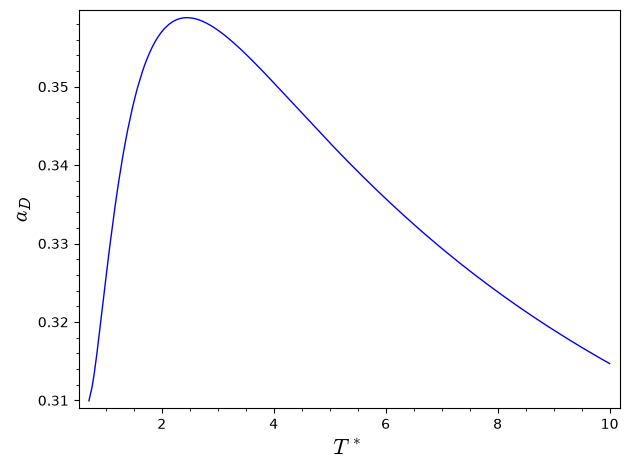

In [11]:
show(plot(a_D, (T, 0.7, 10)), frame=True, axes=False, axes_labels=[r'$T^*$', r'$a_D$'])

## 7. Revised Enskog theory (RET)

RET for Mie fluids (Jervell & Wilhelmsen, *J. Chem. Phys.* **158**, 224101 (2023); **161**, 234106 (2024)), with the contact value $g$ of the radial distribution function from SAFT-VR Mie (Lafitte), evaluated at $r=\sigma$ as in KineticGas, the reference implementation of the authors. The dilute-gas values are the same as in TTT (first Chapman-Enskog approximation, Fokin collision integrals), so that only the density dependence is compared.

* **Self-diffusion** (identical labelled particles, first Enskog approximation): $D_\text{RET}=D_\text{id}/g$. The collisional transfer does not contribute, so $D$ does not depend on the transfer-length model; it is the same in RET-Mie (2023) and RET-EWCA (2024).
* **Viscosity** (RET-EWCA, Eq. (3) of the 2024 paper): $\eta_\text{RET}=\frac{\eta_\text{id}}{g}\left(1+\frac{4\pi}{15}\sigma_p^3\rho g\right)^2+\frac{4}{15}\rho^2\sigma_p^4 g\sqrt{\pi T}$, with the momentum-transfer length $\sigma_p(T)$ of the exchange-weighted closest approach (EWCA), Eq. (14): the distance of closest approach averaged with weight $b\,|\Delta p_\parallel|\propto b\sin^2(\chi/2)$ over impact parameters and relative velocities, with the velocity weight $g^4e^{-g^2/2}$ and $E^*=T^*g^2$ used in KineticGas. The scattering problem includes the attractive part of the LJ potential. Computing $\sigma_p$ takes a few seconds per temperature; the values are cached.

Numerical details of $\sigma_p$: the deflection angle is computed with relative and absolute tolerances of $10^{-6}$; the integrals over the impact parameter exclude a strip of relative width $2\times10^{-6}$ around the orbiting singularity and extend at least up to twice the orbiting impact parameter.

In [12]:
# ---------------- Revised Enskog theory for Mie fluids (RET) ----------------
# Contact RDF from SAFT-VR Mie (Lafitte), evaluated at r = sigma; Jervell & Wilhelmsen (2023).
import numpy as np
from scipy.integrate import quad, quad_vec
from scipy.optimize import brentq
from scipy.special import roots_legendre

eta_r = eta_l
k0_ret = -log(1-eta_r)+(42*eta_r-39*eta_r^2+9*eta_r^3-2*eta_r^4)/(6*(1-eta_r)^3)
k1_ret = (eta_r^4+6*eta_r^2-12*eta_r)/(2*(1-eta_r)^3)
k2_ret = -3*eta_r^2/(8*(1-eta_r)^2)
k3_ret = (-eta_r^4+3*eta_r^2+3*eta_r)/(6*(1-eta_r)^3)
g0_ret = exp(k0_ret+k1_ret*x0_l+k2_ret*x0_l^2+k3_ret*x0_l^3)
g1_ret = (3*diff(a1_l, rho) + C_l/rho*(
    12*x0_l^12*s_l[12]-6*x0_l^6*s_l[6]))/(2*n(pi)*dl^3)
a2_mca_ret = C_l^2/2*khs_l*(
    x0_l^12*s_l[12]-2*x0_l^18*s_l[18]+x0_l^24*s_l[24])
g2_mca_ret = (3*diff(a2_mca_ret, rho) + C_l^2*khs_l/rho*(
    -12*x0_l^24*s_l[24]+18*x0_l^18*s_l[18]-6*x0_l^12*s_l[12]))/(2*n(pi)*dl^3)
gamma_ret = 10*(1-tanh(10*(0.57-alpha_l)))*eta_sigma_l*(exp(1/T)-1)*exp(
    -6.7*eta_sigma_l-8*eta_sigma_l^2)
g_ret = g0_ret*exp((g1_ret/T+(1+gamma_ret)*g2_mca_ret/T^2)/g0_ret)

@lru_cache(maxsize=None)
def ret_rdf_isotherm(temperature):
    return fast_callable(temperature_slice(g_ret, float(temperature)), vars=[rho], domain=RDF)

# ---------------- EWCA momentum-transfer length; Jervell & Wilhelmsen (2024), Eq. (14) ----------------
@lru_cache(maxsize=None)
def ewca_momentum_moments(energy, tolerance=2.e-6r):
    # Integrals over b of (R w, w), with w = b sin^2(chi/2) (momentum weight, Eq. (11)), at reduced energy E*.
    energy = float(energy)
    r0 = (2.r/(1.r+math.sqrt(1.r+energy)))**(1.r/6.r)
    def b_squared(r):
        return r*r + 4.r/energy*(r**(-4r)-r**(-10r))
    critical = None
    if energy < .8r:
        outer = ((4.r+math.sqrt(16.r-20.r*energy))/energy)**(1.r/6.r)
        inner = (20.r/(4.r+math.sqrt(16.r-20.r*energy)))**(1.r/6.r)
        critical = math.sqrt(b_squared(outer))
    def integrand(b):
        if b == 0.r: return np.zeros(2r)
        # Outermost turning point, including attractive near passes.
        if critical is not None and b > critical:
            lo, hi = outer, max(2.r*outer, 2.r*b)
        else:
            lo, hi = r0, inner if critical is not None else max(2.r*r0, 2.r*b)
        R = brentq(lambda r: b_squared(r)-b*b, lo, hi, xtol=2.e-13r)
        a, c, b2 = 4.r/(energy*R**12r), 4.r/(energy*R**6r), (b/R)**2r
        def angle(t):
            u = 1.r-t*t
            s6 = 1.r+u+u*u+u**3r+u**4r+u**5r
            denominator = a*s6*(1.r+u**6r)-c*s6+b2*(1.r+u)
            return 2.r*b/R/math.sqrt(max(denominator, 1.e-300r))
        chi = math.pi-2.r*quad(angle, 0.r, 1.r, epsabs=1.e-6r,
                              epsrel=1.e-6r, limit=200r)[0r]
        weight = b*math.sin(chi/2.r)**2r
        return np.array([R*weight, weight])
    upper = max(10.r, 6.r*r0, 2.r*critical) if critical is not None else max(10.r, 6.r*r0)
    intervals = ([(0.r, critical*(1.r-1.e-6r)), (critical*(1.r+1.e-6r), upper)]
                 if critical is not None else [(0.r, upper)])
    return sum((quad_vec(integrand, lo, hi, epsabs=tolerance,
                         epsrel=tolerance, limit=300r)[0r]
                for lo, hi in intervals), np.zeros(2r))

@lru_cache(maxsize=None)
def ewca_momentum_length(temperature, order=16r, tolerance=2.e-6r):
    # KineticGas convention: E* = T* g^2 and velocity weight g^4 exp(-g^2/2).
    temperature = float(temperature)
    nodes, weights = roots_legendre(int(order))
    bounds = sorted(set([0.r, math.sqrt(.8r/temperature), 1.r, 2.r, 3.5r, 5.r, 8.r]))
    total = np.zeros(2r)
    for lo, hi in zip(bounds[:-1r], bounds[1r:]):
        for node, weight in zip(nodes, weights):
            g = float((hi+lo)/2.r+(hi-lo)/2.r*node)
            total += float(weight)*(hi-lo)/2.r*g**4r*math.exp(-g*g/2.r)*ewca_momentum_moments(
                temperature*g*g, tolerance)
    return float(total[0r]/total[1r])


In [13]:
# ---------------- RET predictions along an isotherm ----------------
# First Enskog approximation, with the same dilute-gas values as TTT (Fokin collision integrals).
@lru_cache(maxsize=None)
def ret_isotherm(temperature, key):
    temperature = float(temperature)
    rdf = ret_rdf_isotherm(temperature)
    if key == 'rhoD':
        # Labelled identical particles: rho D = rho D_id / g; no collisional transfer (RET-Mie, 2023).
        dilute = float(rhoD_id(T=temperature))
        def value(density):
            return dilute if density == 0 else dilute/float(rdf(float(density)))
    elif key == 'eta':
        # Eq. (3) of Jervell & Wilhelmsen (2024) with the EWCA momentum-transfer length.
        dilute, mtl = float(eta_id(T=temperature)), ewca_momentum_length(temperature)
        def value(density):
            density = float(density)
            if density == 0:
                return dilute
            g = float(rdf(density))
            return (dilute/g*(1.+4.*math.pi/15.*mtl**3*density*g)**2
                    + 4./15.*density**2*mtl**4*g*math.sqrt(math.pi*temperature))
    else:
        raise ValueError('Unknown RET property: ' + str(key))
    return value

show(table([[format(float(t), 'g'), '%.4f' % ewca_momentum_length(t)] for t in T_super],
           header_row=['T*', 'sigma_p (EWCA)']))


T*,sigma_p (EWCA)
1.5,0.9672
1.8,0.9523
2.1,0.9402
2.5,0.9271
3,0.9141
4,0.8948
6,0.8692


## 8. Figures and tables of the paper (supercritical temperatures)

Square panels, saved as PDF next to `tttLJ.tex` (`FIGURE_DIR`). MD data of Meier for the full LJ fluid. Only supercritical temperatures are shown: close to the critical point the TTT result is very sensitive to the changes of curvature of the free energy. In the TTT panels with the full-LJ EOS, the gray region lies beyond the freezing line (Sec. 5).

* **Self-diffusion:** MAPE for all the data with $\rho^*\le1.2$ (all of them below the freezing density).
* **Viscosity:** MAPE for $\rho^*\le0.8$, because of the proximity of the freezing line; panels with $\rho^*\le0.9$ and $\eta^*\le3$. With the Heier EOS (LJTS, $r_c=2.5$), the curves end, and the MAPE is restricted, where the pressure of the EOS reaches $p^*=6.8$, the upper limit of the range in which it was validated.

Tables show percentages with two significant digits.

In [14]:
import os

# ---------------- Panels and MAPE tables for the paper ----------------
FIGURE_DIR = '..'          # the figures are written next to tttLJ.tex
PANEL_SIZE = [4.8, 4.8]
RHO_MAPE_D = RHO_MAX_MAPE  # self-diffusion: all data with rho* <= 1.2
RHO_MAPE_ETA = 0.8         # viscosity: rho* <= 0.8 (proximity of the freezing line)
XMAX_ETA, YMAX_ETA_PAPER = 0.9, 3
P_MAX_HEIER = 6.8

def two_digits(value):
    return format(float(value), '#.2g').rstrip('.') if math.isfinite(value) else 'N/A'

def paper_panel(data, temperatures, key, ylabel, xmax, ymax, rho_mape, title,
                eos=None, ret=False, freezing=None, p_max=None, legend_loc='upper left'):
    # One panel: MD symbols and either RET (ret=True) or TTT with the EOS `eos`.
    # Returns (graph, plot options, {T: MAPE}).
    graph = Graphics()
    if freezing is not None:
        graph += freezing_region(rT_function(eos, MODELS[eos['name']][key]), freezing, xmax, ymax)
    errors = {}
    for k, t in enumerate(temperatures):
        color = colors[k % len(colors)]
        graph += points([p for p in data[t] if p[0] <= xmax], marker='o', size=25, color=color,
                        zorder=3, legend_label=r'$T^*=$' + format(float(t), 'g'))
        if ret:
            f, end = ret_isotherm(t, key), xmax
            graph += line([(xmax*i/300., f(xmax*i/300.)) for i in range(301)],
                          color=color, thickness=1.5)
        else:
            f = isotherm(MODELS[eos['name']][key], eos, t)
            end = xmax if p_max is None else rho_at_pressure(eos, t, p_max, xmax)
            graph += plot(f, (rho, 0.002, end), color=color, thickness=1.5)
        errors[t] = mape(f, data[t], min(rho_mape, end))[0]
    options = dict(xmin=0, xmax=xmax, ymin=0, ymax=ymax, frame=True, axes=False, title=title,
                   axes_labels=[r'$\rho^*$', ylabel], fontsize=12, legend_font_size=10,
                   aspect_ratio='automatic', figsize=PANEL_SIZE)
    graph.set_legend_options(loc=legend_loc, handlelength=2, markerscale=1, font_weight='normal')
    return graph, options, errors

def save_panel(graph, options, filename):
    show(graph, **options)
    graph.save(os.path.join(FIGURE_DIR, filename), **options)

def mape_table_paper(name, temperatures, columns, headers, rho_mape):
    rows = [[format(float(t), 'g')] + [two_digits(col[t]) for col in columns] for t in temperatures]
    print(name + ': MAPE (%) for rho* <= ' + format(float(rho_mape), 'g'))
    show(table(rows, header_row=['T*'] + headers))
    lines = [r'\begin{tabular}{' + 'c'*(len(headers)+1) + '}', r'\hline\hline',
             r'$T^*$ & ' + ' & '.join(headers) + r' \\', r'\hline']
    lines += [' & '.join(row) + r' \\' for row in rows]
    lines += [r'\hline\hline', r'\end{tabular}']
    print('\n'.join(lines))
    return rows


### 8.1 Self-diffusion: RET and TTT (Thol EOS)

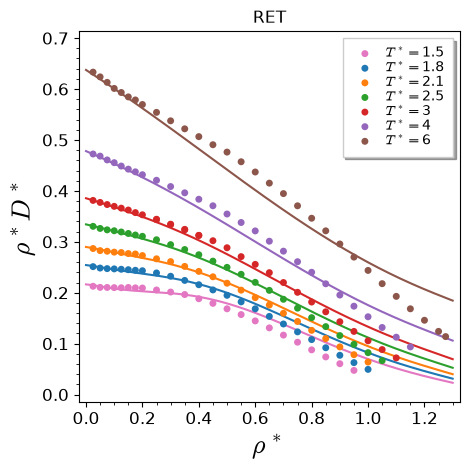

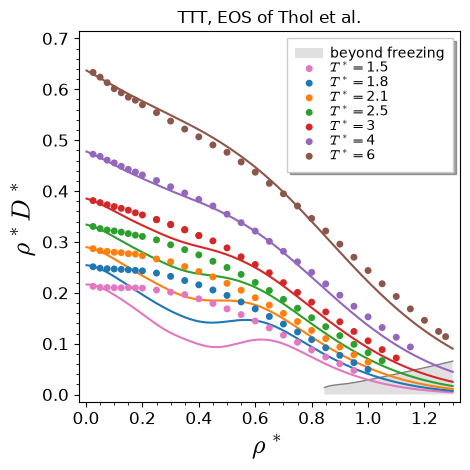

Self-diffusion: MAPE (%) for rho* <= 1.2


T*,RET,TTT
1.5,13,23
1.8,11,16
2.1,7.5,12
2.5,7.0,8.4
3,6.6,6.1
4,7.1,3.5
6,7.0,3.7


\begin{tabular}{ccc}
\hline\hline
$T^*$ & RET & TTT \\
\hline
1.5 & 13 & 23 \\
1.8 & 11 & 16 \\
2.1 & 7.5 & 12 \\
2.5 & 7.0 & 8.4 \\
3 & 6.6 & 6.1 \\
4 & 7.1 & 3.5 \\
6 & 7.0 & 3.7 \\
\hline\hline
\end{tabular}


In [15]:
gD_ret, oD_ret, eD_ret = paper_panel(D_meier, T_super, 'rhoD', r'$\rho^* D^*$', XMAX_SUPER, YMAX_D,
                                     RHO_MAPE_D, 'RET', ret=True, legend_loc='upper right')
gD_ttt, oD_ttt, eD_ttt = paper_panel(D_meier, T_super, 'rhoD', r'$\rho^* D^*$', XMAX_SUPER, YMAX_D,
                                     RHO_MAPE_D, 'TTT, EOS of Thol et al.', eos=eos_thol,
                                     freezing='LJ', legend_loc='upper right')
save_panel(gD_ret, oD_ret, 'fig_D_RET.pdf')
save_panel(gD_ttt, oD_ttt, 'fig_D_TTT_Thol.pdf')
rows_D_paper = mape_table_paper('Self-diffusion', T_super, [eD_ret, eD_ttt], ['RET', 'TTT'], RHO_MAPE_D)

In [16]:
# TTT with other EOS for the full LJ fluid (errors mentioned in the paper)
eD_kolafa = {t: mape(isotherm(MODELS['Kolafa']['rhoD'], eos_kolafa, t), D_meier[t], RHO_MAPE_D)[0] for t in T_super}
eD_lafitte = {t: mape(isotherm(MODELS['Lafitte']['rhoD'], eos_lafitte, t), D_meier[t], RHO_MAPE_D)[0] for t in T_super}
_ = mape_table_paper('Self-diffusion, TTT with several EOS', T_super, [eD_ttt, eD_kolafa, eD_lafitte],
                     ['Thol', 'Kolafa', 'Lafitte'], RHO_MAPE_D)

Self-diffusion, TTT with several EOS: MAPE (%) for rho* <= 1.2


T*,Thol,Kolafa,Lafitte
1.5,23,22,21
1.8,16,17,15
2.1,12,12,11
2.5,8.4,8.9,7.6
3,6.1,6.5,5.2
4,3.5,4.0,3.2
6,3.7,4.4,4.5


\begin{tabular}{cccc}
\hline\hline
$T^*$ & Thol & Kolafa & Lafitte \\
\hline
1.5 & 23 & 22 & 21 \\
1.8 & 16 & 17 & 15 \\
2.1 & 12 & 12 & 11 \\
2.5 & 8.4 & 8.9 & 7.6 \\
3 & 6.1 & 6.5 & 5.2 \\
4 & 3.5 & 4.0 & 3.2 \\
6 & 3.7 & 4.4 & 4.5 \\
\hline\hline
\end{tabular}


### 8.2 Viscosity: RET-EWCA, TTT (Thol EOS) and TTT (Heier EOS)

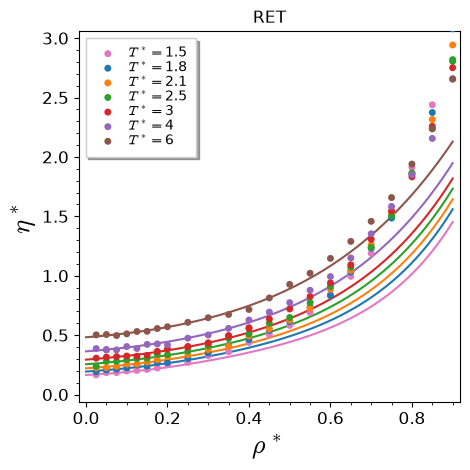

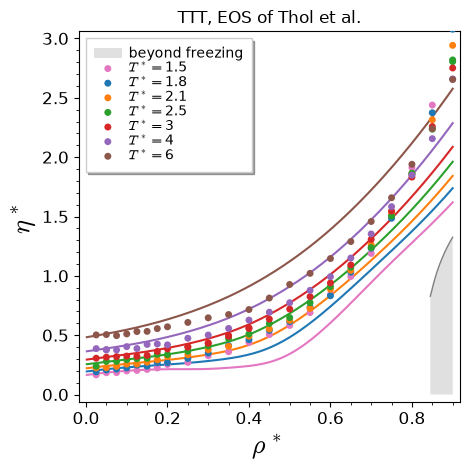

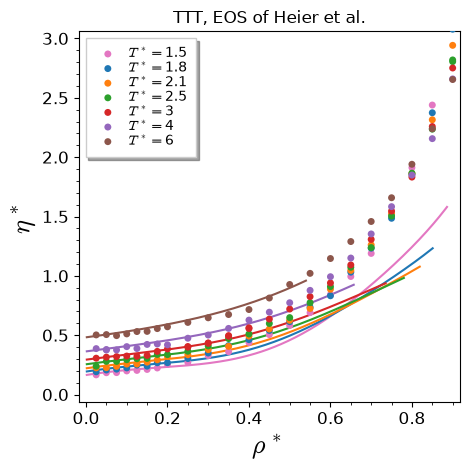

Viscosity: MAPE (%) for rho* <= 0.8


T*,RET,TTT Thol,TTT Heier
1.5,18,21,15
1.8,15,13,15
2.1,12,7.7,15
2.5,11,3.6,12
3,7.4,5.5,8.3
4,5.5,10,6.2
6,3.5,14,3.6


\begin{tabular}{cccc}
\hline\hline
$T^*$ & RET & TTT Thol & TTT Heier \\
\hline
1.5 & 18 & 21 & 15 \\
1.8 & 15 & 13 & 15 \\
2.1 & 12 & 7.7 & 15 \\
2.5 & 11 & 3.6 & 12 \\
3 & 7.4 & 5.5 & 8.3 \\
4 & 5.5 & 10 & 6.2 \\
6 & 3.5 & 14 & 3.6 \\
\hline\hline
\end{tabular}


T*,rho* at p* = 6.8 (Heier)
1.5,0.886
1.8,0.851
2.1,0.819
2.5,0.780
3,0.735
4,0.657
6,0.540


In [17]:
gE_ret, oE_ret, eE_ret = paper_panel(eta_meier, T_super, 'eta', r'$\eta^*$', XMAX_ETA, YMAX_ETA_PAPER,
                                     RHO_MAPE_ETA, 'RET', ret=True)
gE_ttt, oE_ttt, eE_ttt = paper_panel(eta_meier, T_super, 'eta', r'$\eta^*$', XMAX_ETA, YMAX_ETA_PAPER,
                                     RHO_MAPE_ETA, 'TTT, EOS of Thol et al.', eos=eos_thol, freezing='LJ')
gE_hei, oE_hei, eE_hei = paper_panel(eta_meier, T_super, 'eta', r'$\eta^*$', XMAX_ETA, YMAX_ETA_PAPER,
                                     RHO_MAPE_ETA, 'TTT, EOS of Heier et al.', eos=eos_heier,
                                     p_max=P_MAX_HEIER)
save_panel(gE_ret, oE_ret, 'fig_eta_RET.pdf')
save_panel(gE_ttt, oE_ttt, 'fig_eta_TTT_Thol.pdf')
save_panel(gE_hei, oE_hei, 'fig_eta_TTT_Heier.pdf')
rows_eta_paper = mape_table_paper('Viscosity', T_super, [eE_ret, eE_ttt, eE_hei],
                                  ['RET', 'TTT Thol', 'TTT Heier'], RHO_MAPE_ETA)
show(table([[format(float(t), 'g'), '%.3f' % rho_at_pressure(eos_heier, t, P_MAX_HEIER, XMAX_ETA)]
            for t in T_super], header_row=['T*', 'rho* at p* = 6.8 (Heier)']))

In [18]:
# TTT with other EOS for the full LJ fluid (errors mentioned in the paper)
eE_kolafa = {t: mape(isotherm(MODELS['Kolafa']['eta'], eos_kolafa, t), eta_meier[t], RHO_MAPE_ETA)[0] for t in T_super}
eE_lafitte = {t: mape(isotherm(MODELS['Lafitte']['eta'], eos_lafitte, t), eta_meier[t], RHO_MAPE_ETA)[0] for t in T_super}
_ = mape_table_paper('Viscosity, TTT with several EOS', T_super, [eE_ttt, eE_kolafa, eE_lafitte],
                     ['Thol', 'Kolafa', 'Lafitte'], RHO_MAPE_ETA)

Viscosity, TTT with several EOS: MAPE (%) for rho* <= 0.8


T*,Thol,Kolafa,Lafitte
1.5,21,20,17
1.8,13,14,12
2.1,7.7,8.5,7.2
2.5,3.6,3.7,3.5
3,5.5,5.1,5.7
4,10,10,11
6,14,14,15


\begin{tabular}{cccc}
\hline\hline
$T^*$ & Thol & Kolafa & Lafitte \\
\hline
1.5 & 21 & 20 & 17 \\
1.8 & 13 & 14 & 12 \\
2.1 & 7.7 & 8.5 & 7.2 \\
2.5 & 3.6 & 3.7 & 3.5 \\
3 & 5.5 & 5.1 & 5.7 \\
4 & 10 & 10 & 11 \\
6 & 14 & 14 & 15 \\
\hline\hline
\end{tabular}
